In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/lakshmideepikapeyala/linkedinjobposings/linkedin job postings.csv


In [2]:
import pandas as pd
import numpy as np

# Load the data
df = pd.read_csv('/kaggle/input/datasets/lakshmideepikapeyala/linkedinjobposings/linkedin job postings.csv')
print("Original rows:", len(df))

# Remove duplicates (same cleaning as SQL)
df = df.drop_duplicates(subset=['job_id', 'job_title', 'company_name', 'posting_date'])
print("After removing duplicates:", len(df))

# Clean company names
df['company_name'] = df['company_name'].str.strip()

# Fill missing values
df['company_size'] = df['company_size'].fillna('Unknown')
df['required_skills'] = df['required_skills'].fillna('Not Specified')

print("\nMissing values now:")
print(df[['salary_min_lpa', 'company_size', 'required_skills']].isna().sum())

df.head()

Original rows: 6293
After removing duplicates: 6200

Missing values now:
salary_min_lpa     372
company_size         0
required_skills      0
dtype: int64


,job_id,job_title,experience_level,company_name,industry,location,job_type,employment_type,company_size,min_experience_years,max_experience_years,salary_min_lpa,salary_max_lpa,required_skills,posting_date,applicants_count,job_id_row
0,JOB03826,Data Scientist,Senior,Ola,Fintech,Remote - India,Onsite,Full-time,1-50,5.3,6.4,21.1,22.7,"SQL, Python, Scikit-learn, SAS",2026-02-06,72,1
1,JOB01410,Power BI Developer,Mid,Cognizant,IT Services,"Kolkata, West Bengal",Onsite,Full-time,1-50,3.7,5.9,10.0,15.6,"SQL, Power BI, DAX, Data Modeling, Dashboarding",2025-09-07,58,2
2,JOB00136,BI Analyst,Entry,Deloitte,EdTech,Remote,Onsite,Internship,51-200,0.3,2.7,4.5,7.6,"Power BI, DAX, Tableau, Dashboarding",2025-02-24,56,3
3,JOB02247,Analytics Intern,Entry,HCLTech,Fintech,"Bengaluru, Karnataka",Onsite,Full-time,201-1000,0.1,1.6,NaN,NaN,"SQL, Python, Excel, Communication",2026-02-09,33,4
4,JOB02417,Data Scientist,Mid,zomato,Manufacturing,"Hyderabad, Telangana",Onsite,Full-time,1001-5000,2.7,3.8,8.7,10.0,"Machine Learning, Deep Learning, Statistics, P...",2025-12-15,94,5


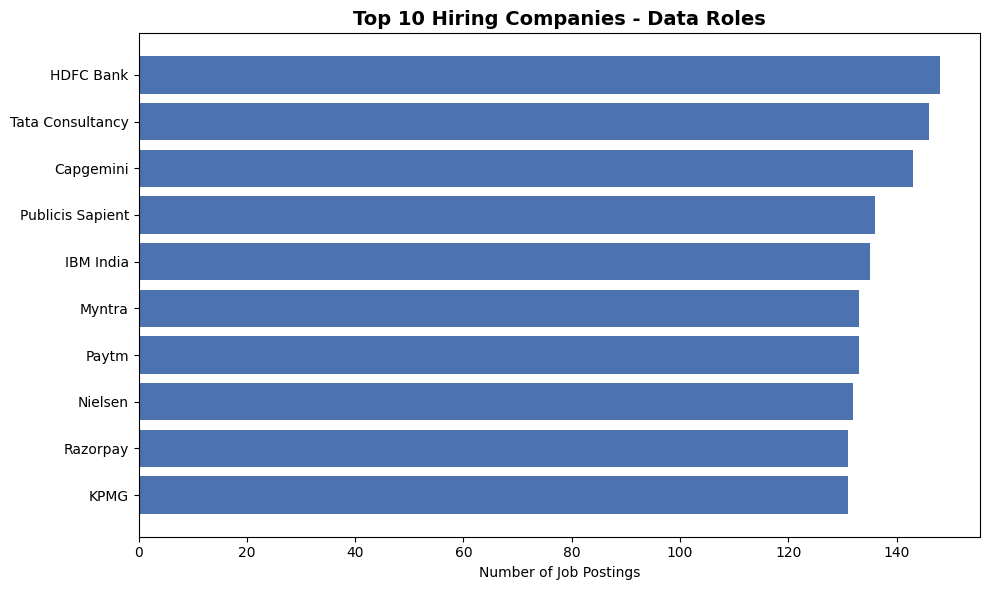

In [3]:
import matplotlib.pyplot as plt

top_companies = df['company_name'].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_companies.index[::-1], top_companies.values[::-1], color='#4C72B0')
plt.xlabel('Number of Job Postings')
plt.title('Top 10 Hiring Companies - Data Roles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('top_companies.png', dpi=150)
plt.show()

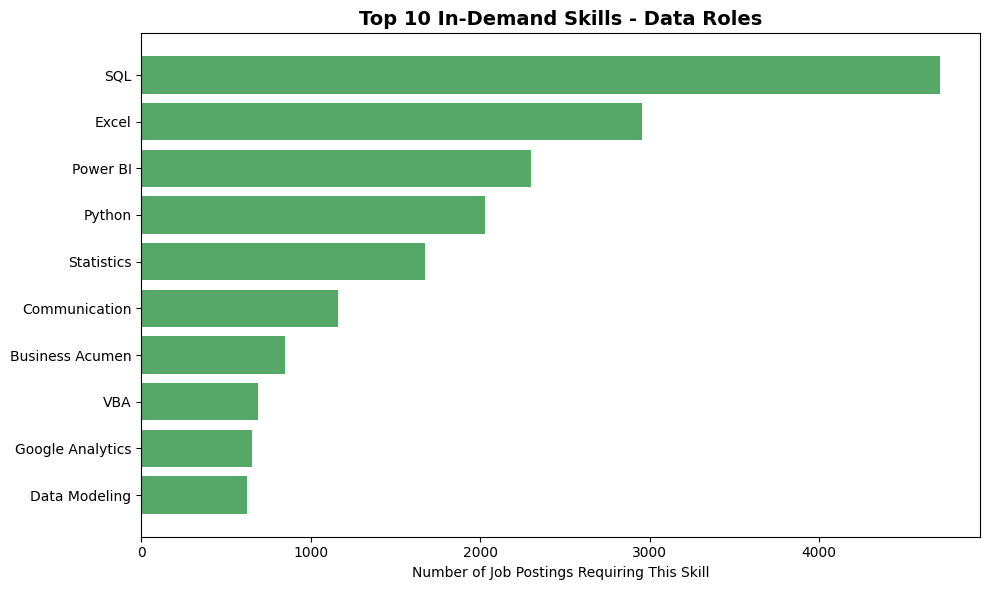

In [4]:
from collections import Counter

# Split and count all skills
all_skills = df[df['required_skills'] != 'Not Specified']['required_skills'].str.split(', ')
skill_counts = Counter([skill for sublist in all_skills for skill in sublist])

top_skills = dict(sorted(skill_counts.items(), key=lambda x: x[1], reverse=True)[:10])

plt.figure(figsize=(10, 6))
plt.barh(list(top_skills.keys())[::-1], list(top_skills.values())[::-1], color='#55A868')
plt.xlabel('Number of Job Postings Requiring This Skill')
plt.title('Top 10 In-Demand Skills - Data Roles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('top_skills.png', dpi=150)
plt.show()

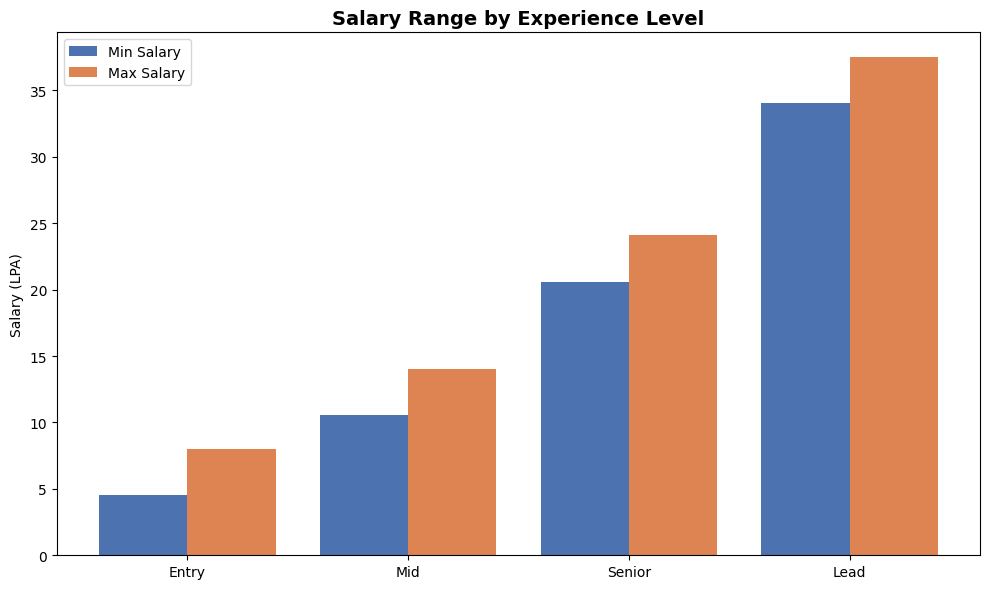

In [5]:
salary_by_level = df.groupby('experience_level')[['salary_min_lpa', 'salary_max_lpa']].mean().reindex(['Entry', 'Mid', 'Senior', 'Lead'])

x = range(len(salary_by_level))
plt.figure(figsize=(10, 6))
plt.bar([i - 0.2 for i in x], salary_by_level['salary_min_lpa'], width=0.4, label='Min Salary', color='#4C72B0')
plt.bar([i + 0.2 for i in x], salary_by_level['salary_max_lpa'], width=0.4, label='Max Salary', color='#DD8452')
plt.xticks(x, salary_by_level.index)
plt.ylabel('Salary (LPA)')
plt.title('Salary Range by Experience Level', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('salary_by_level.png', dpi=150)
plt.show()

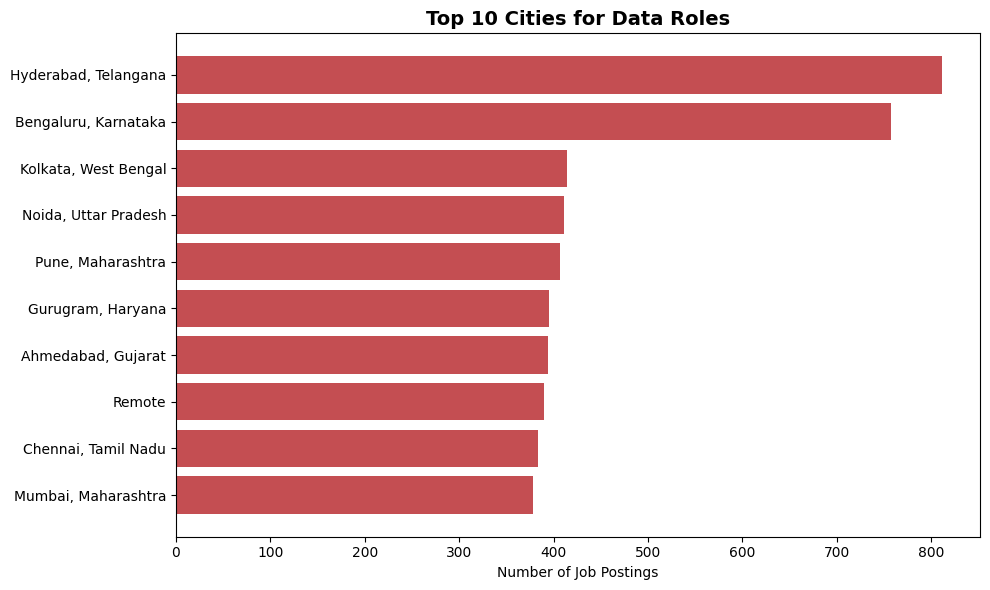

In [6]:
top_locations = df['location'].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_locations.index[::-1], top_locations.values[::-1], color='#C44E52')
plt.xlabel('Number of Job Postings')
plt.title('Top 10 Cities for Data Roles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('top_locations.png', dpi=150)
plt.show()

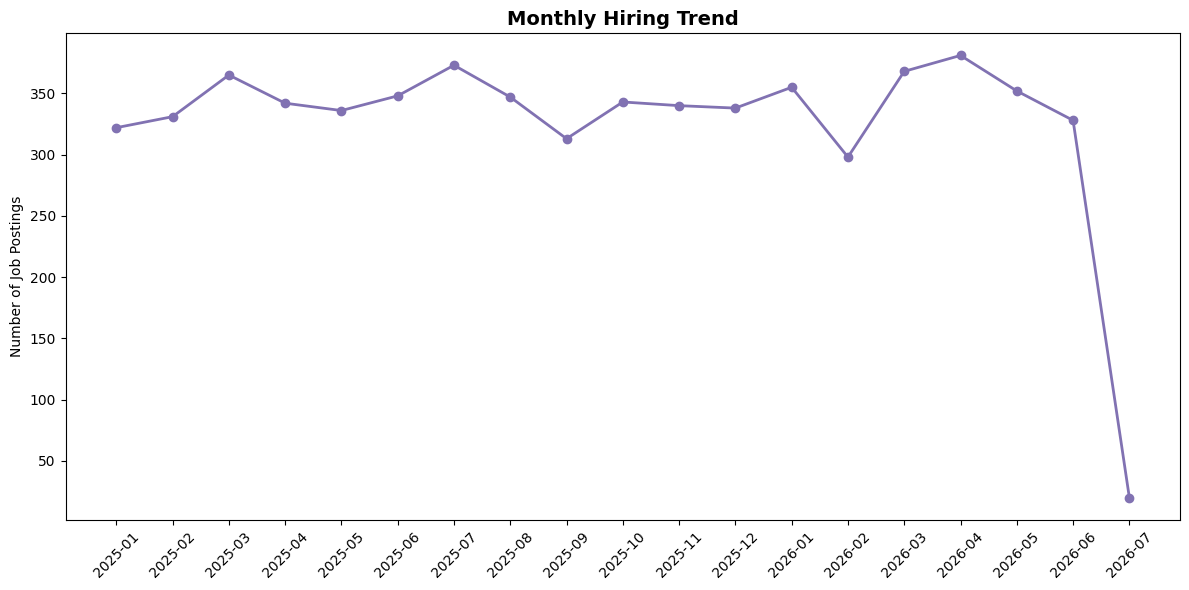

In [7]:
df['posting_date'] = pd.to_datetime(df['posting_date'])
df['month'] = df['posting_date'].dt.to_period('M').astype(str)

monthly_trend = df.groupby('month').size()

plt.figure(figsize=(12, 6))
plt.plot(monthly_trend.index, monthly_trend.values, marker='o', color='#8172B2', linewidth=2)
plt.xticks(rotation=45)
plt.ylabel('Number of Job Postings')
plt.title('Monthly Hiring Trend', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('hiring_trend.png', dpi=150)
plt.show()